# Nav2 behaviour-tree coverage: audit of the **random** campaigns

These are **random** TurtleBot4 + Nav2 campaigns run in **RoboVAST** against a
**roqsim**-driven ROS 2 stack. Unlike the QD audits there is no optimiser here -- each
campaign is a random draw of `PathVariationRandom` scenario parameters:

* a start/goal pose pair in free space,
* the controller (50/50 MPPI/DWB) and planner (`use_astar` True/False),
* a static obstacle (50 %, random pose, 0.5x0.5x1.0 m),
* a dynamic obstacle (50 %, random pose, spawned when the robot comes within a random
  0-5 m trigger distance).

Only behaviour-tree coverage is analysed here.

This notebook is written to **scale to many campaigns**. It auto-discovers every
`random-*` campaign under `truely_random/`, runs the same audit on each, and finishes with a
coverage summary table in the style of the paper's Table III. Adding the remaining
`nav_through_poses` / `follow_waypoints` campaigns requires **no edits** -- drop them in
`truely_random/` and re-run.

For each campaign it asks:

1. Which tree was used and how coverage is calculated.
2. How much of the tree each run exercised, and the distribution over the draws.
3. Which nodes were (and were never) covered.
4. How the random scenario parameters (controller, planner, obstacles, path length) drive
   coverage.
5. A **cross-campaign coverage summary** at the end (best coverage, share at 100 %, share
   failure-free).

### Setup

In [11]:
# Needs pandas, numpy, matplotlib, seaborn, pyyaml, networkx.
from __future__ import annotations
import csv, json, re, sqlite3
from pathlib import Path
from xml.etree import ElementTree
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

try:
    import networkx as nx
except ImportError:  # the tree figure degrades to bar charts only
    nx = None

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
RANDOM_ROOT = DATA_ROOT / "truely_random"
WORLD_LABEL = {"hexagon": "hexagon", "secorolab": "offices (secorolab)"}
TASK_TEX = {"nav_to_pose": r"\navtopose{}",
            "nav_through_poses": r"\navthroughposes{}",
            "follow_waypoints": r"\followwaypoints{}"}
ENV_TEX = {"hexagon": r"\tbworld{}", "secorolab": r"\offices{}"}


def _campaign_dirs(root):
    """Yield campaign directories directly under root. Descends one level into a
    '<name>.incomplete/<name>' wrapper so a half-finished campaign is still found."""
    for entry in sorted(root.iterdir()):
        if not entry.is_dir():
            continue
        if (entry / "_config").is_dir():
            yield entry
        else:
            for sub in sorted(entry.iterdir()):
                if sub.is_dir() and (sub / "_config").is_dir():
                    yield sub


def _load_vast(path):
    try:
        return yaml.safe_load(path.read_text())
    except Exception:
        return None


def _find_key(obj, key, default=None):
    """Depth-first search for the first occurrence of key in nested dicts/lists."""
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for v in obj.values():
            r = _find_key(v, key, None)
            if r is not None:
                return r
    elif isinstance(obj, list):
        for v in obj:
            r = _find_key(v, key, None)
            if r is not None:
                return r
    return default


def discover_campaigns(root=RANDOM_ROOT):
    """Auto-discover every random campaign under truely_random/."""
    found = {}
    for c in _campaign_dirs(root):
        vasts = sorted((c / "_config").glob("*.vast"))
        if not vasts:
            continue
        vast_path = vasts[0]
        vast = _load_vast(vast_path) or {}
        meta = (vast.get("metadata") or {}).get("name") or vast_path.stem
        meta = re.sub(r"^random_", "", str(meta))
        parts = meta.split("_")
        world = parts[0]
        task = "_".join(parts[1:]) if len(parts) > 1 else "unknown"
        bt_rel = _find_key(vast, "bt_xml")
        if bt_rel is None:
            mm = re.search(r"bt_xml:\s*(\S+)", vast_path.read_text())
            bt_rel = mm.group(1) if mm else "files/navigate_to_pose_w_replanning_and_recovery.xml"
        found[f"{world}-{task}"] = dict(
            key=f"{world}-{task}", root=c, name=c.name, world=world, task=task,
            world_label=WORLD_LABEL.get(world, world), vast=vast_path,
            bt_xml=c / "_config" / bt_rel)
    return found


CAMPAIGNS = discover_campaigns()
print(f"discovered {len(CAMPAIGNS)} random campaign(s) under {RANDOM_ROOT.name}/:")
for k, c in CAMPAIGNS.items():
    print(f"  [{k}]  world={c['world']:<10} task={c['task']:<18} "
          f"bt_xml={c['bt_xml'].name}  ({c['name']})")

discovered 3 random campaign(s) under truely_random/:
  [hexagon-nav_through_poses]  world=hexagon    task=nav_through_poses  bt_xml=navigate_through_poses_w_replanning_and_recovery.xml  (random-hexagon-nav-through-poses-2026-09-16-22475341)
  [hexagon-nav_to_pose]  world=hexagon    task=nav_to_pose        bt_xml=navigate_to_pose_w_replanning_and_recovery.xml  (random-hexagon-nav-to-pose-2026-09-16-20142397)
  [secorolab-nav_to_pose]  world=secorolab  task=nav_to_pose        bt_xml=navigate_to_pose_w_replanning_and_recovery.xml  (random-secorolab-nav-to-pose-2026-09-16-22024739)


## 3. Which tree was used, and how coverage is calculated

**The tree.** Each campaign's `.vast` feeds `nav2_bt_tree` (and the coverage extractor) the
`files/..._w_replanning_and_recovery.xml` named by its `bt_xml` key -- the same file nav2
runs via `bt_navigator`. We flatten it the same way RoboVAST does: every XML element below
`<BehaviorTree>` is one node, named by its `name` attribute (else its tag), with `<SubTree>`
references expanded inline (cycle-guarded). Coverage is counted over distinct **names**, not
per-instance slots (the XML has more node *instances* than distinct names).

**The formula** -- `_config/search/bt_coverage.py`, which defines this package's objective:

```python
declared = distinct node names in the XML
reached  = node names in /behavior_tree_log (written to nav2_behaviors.csv)
           whose status_name != INVALID          # INVALID == never ticked
coverage = len(reached) / len(declared)
```

A node counts as covered whether it returned `SUCCESS` or `FAILURE` -- *any* non-`INVALID`
transition. The score is therefore **breadth of code ticked**, and the cheapest way to raise
it is to get the robot stuck so the whole recovery subtree runs once. `behaviour_kinds`
counts how many of the three behaviour-server actions (`Spin`, `Wait`, `BackUp`) fired, i.e.
how much of the recovery payload a run reached.

In [12]:
def parse_bt_xml(xml_path):
    """Flatten a BehaviorTree.CPP XML the way RoboVAST does (see section 3)."""
    root = ElementTree.parse(xml_path).getroot()
    trees = {bt.get("ID"): bt for bt in root.iter("BehaviorTree")}
    main_id = root.get("main_tree_to_execute")
    main = trees.get(main_id) if main_id else None
    if main is None:
        main = next(iter(trees.values()), None)
    name_of = lambda el: el.get("name") or el.tag
    names, parents, classes = [], {}, {}

    def walk(el, pid, active):
        nid = len(names)
        names.append(name_of(el)); parents[nid] = pid; classes[nid] = el.tag
        me = nid
        for ch in list(el):
            if ch.tag == "SubTree":
                ref = ch.get("ID"); sub = trees.get(ref)
                if sub is not None and ref not in active:
                    for sc in list(sub):
                        walk(sc, me, active | {ref})
                continue
            walk(ch, me, active)

    for ch in list(main):
        walk(ch, None, frozenset({main_id} if main_id else set()))
    return dict(names=names, parents=parents, classes=classes, declared=set(names))


def load_rows(camp):
    """One row per run, from each <config>/<rep>/bt_coverage.csv (the BtCoverage file)."""
    rows = []
    for cfgdir in sorted(d for d in camp["root"].iterdir()
                         if d.is_dir() and not d.name.startswith("_")):
        reps = [d for d in sorted(cfgdir.iterdir()) if d.is_dir()]
        got = False
        for rep in reps:
            bc = rep / "bt_coverage.csv"
            if not bc.exists():
                continue
            with open(bc) as f:
                r = next(csv.DictReader(f))
            d = dict(config_name=cfgdir.name, run=rep.name)
            # keep only the coverage columns from bt_coverage.csv
            d.update({k: int(v) for k, v in r.items()
                      if k in ("nodes_total", "nodes_reached",
                               "behaviour_kinds", "behaviour_ticks")})
            d["behaviours"] = r["behaviours"]
            d["measured"] = True
            rows.append(d)
            got = True
        if not got:
            rows.append(dict(config_name=cfgdir.name, run="", behaviours="",
                             nodes_total=0, nodes_reached=0, behaviour_kinds=0,
                             behaviour_ticks=0, measured=False))
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows).set_index("config_name").sort_index()
    df["coverage"] = df["nodes_reached"] / df["nodes_total"].replace(0, np.nan)
    return df


def tab_reached(csv_path):
    """Per-file {node name} accounting from the transition CSV. Only non-INVALID statuses
    are real transitions; INVALID is the postprocessor's 'never ticked' baseline."""
    total, reached = set(), set()
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            name = row["behavior_name"]
            total.add(name)
            if row.get("status_name", "INVALID") != "INVALID":
                reached.add(name)
    return total, reached


def config_params(camp):
    """{config_name: params_json} from the campaign DB."""
    conn = sqlite3.connect(camp["root"] / "campaign.db")
    try:
        return {u[0]: json.loads(u[1])
                for u in conn.execute("SELECT config_name, params_json FROM unit")}
    finally:
        conn.close()


def goal_points(pj):
    """(x, y) of the final goal for a config, tolerant of task variants (used for the
    scenario's path length)."""
    for key in ("goal_pose", "goal_poses", "goals", "waypoints", "poses"):
        if key not in pj:
            continue
        v = pj[key]
        items = v if isinstance(v, list) else [v]
        pts = []
        for it in items:
            pos = (it.get("position", it) if isinstance(it, dict) else None)
            if pos and "x" in pos and "y" in pos:
                pts.append((float(pos["x"]), float(pos["y"])))
        if pts:
            return pts[-1]
    return None


def vast_flags(camp):
    """{config_name: {static, dynamic}} read from the .vast configuration section."""
    vast = _load_vast(camp["vast"]) or {}
    flags = {}
    for unit in vast.get("configuration", []) or []:
        p = unit.get("parameters") or {}
        sc = p.get("scenario", {}) or {}
        comps = ((p.get("sim") or {}).get("overrides") or {}).get("components", {}) or {}
        flags[unit.get("name")] = dict(
            static=bool((comps.get("static_obstacles") or {}).get("instances")),
            dynamic=("spawn_trigger_point" in sc))
    return flags


def parameter_frame(camp, measured, pj):
    """One row per measured run with the scenario parameters that were drawn, plus
    coverage and behaviour_kinds."""
    flags = vast_flags(camp)
    recs = []
    for cfg, m in measured.iterrows():
        p = pj.get(cfg, {})
        pf = str(p.get("params_file", ""))
        s = (p.get("start_pose") or {}).get("position")
        g = goal_points(p)
        rec = dict(config_name=cfg,
                   controller="MPPI" if "mppi" in pf else "DWB",
                   astar="astar1" in pf,
                   static=flags.get(cfg, {}).get("static"),
                   dynamic=flags.get(cfg, {}).get("dynamic"),
                   coverage=m["coverage"], kinds=m["behaviour_kinds"])
        if s and g:
            rec["path_len"] = float(np.hypot(s["x"] - g[0], s["y"] - g[1]))
        recs.append(rec)
    return pd.DataFrame(recs).set_index("config_name") if recs else pd.DataFrame()

## 4. Per-campaign analysis

`analyse(camp)` runs the whole audit for one campaign and returns every intermediate frame
plus a flat `summary_row` (best coverage, share at 100 %, share failure-free). The next cell
loops it over every auto-discovered campaign and prints the detailed report; later cells
compare the campaigns and tabulate them.

In [13]:
def analyse(camp):
    T = parse_bt_xml(camp["bt_xml"])
    rows = load_rows(camp)
    if len(rows):
        measured = rows[rows["measured"]].copy()
        missing = rows.index[~rows["measured"]].tolist()
    else:
        measured, missing = rows, []

    pj = config_params(camp)
    pall = parameter_frame(camp, measured, pj)

    # per-node reach fraction: which declared node left INVALID, from the transition log
    node_frac, n_node_runs = {}, 0
    for cfg, mrow in measured.iterrows():
        run = mrow.get("run", "") or "0"
        csvp = camp["root"] / cfg / run / "nav2_behaviors.csv"
        if not csvp.exists():
            cands = sorted((camp["root"] / cfg).glob("*/nav2_behaviors.csv"))
            if not cands:
                continue
            csvp = cands[0]
        n_node_runs += 1
        _, reached = tab_reached(csvp)
        for nd in reached & T["declared"]:
            node_frac[nd] = node_frac.get(nd, 0) + 1
    if n_node_runs:
        node_frac = {nd: node_frac.get(nd, 0) / n_node_runs for nd in T["declared"]}

    # best single configuration (highest mean per-run coverage of any concrete scenario)
    if len(measured):
        cov_by_cfg = measured.groupby(level=0)["coverage"].mean()
        best_cfg = cov_by_cfg.idxmax()
        best_cfg_cov = float(cov_by_cfg.loc[best_cfg])
        fail_free_nodes = int(measured["nodes_reached"].min())
    else:
        best_cfg, best_cfg_cov, fail_free_nodes = None, np.nan, 0

    return dict(camp=camp, T=T, rows=rows, measured=measured, missing=missing,
                pj=pj, pall=pall, node_frac=node_frac, n_declared=len(T["declared"]),
                best_cfg=best_cfg, best_cfg_cov=best_cfg_cov,
                failure_free_nodes=fail_free_nodes)


def summary_row(r):
    camp, m = r["camp"], r["measured"]
    n = len(m)
    cov = m["coverage"].dropna() if n else pd.Series(dtype=float)
    vc = m["nodes_reached"].value_counts() if n else pd.Series(dtype=int)
    baseline_n = int(vc.iloc[0]) if len(vc) else 0
    union = {nd for nd, f in r["node_frac"].items() if f > 0}
    runs_100 = int((m["nodes_reached"] == r["n_declared"]).sum()) if n else 0
    ff = int((m["nodes_reached"] == r["failure_free_nodes"]).sum()) if n else 0
    return dict(
        campaign=camp["key"], world=camp["world_label"], task=camp["task"],
        n_configs=len(r["rows"]), n_measured=n, nodes_declared=r["n_declared"],
        best_mean_coverage=round(r["best_cfg_cov"], 3) if pd.notna(r["best_cfg_cov"]) else np.nan,
        best_config=r["best_cfg"],
        best_run_coverage=round(m["coverage"].max(), 3) if n else np.nan,
        runs_at_100=runs_100,
        runs_at_100_pct=round(100 * runs_100 / n, 1) if n else np.nan,
        failure_free_nodes=r["failure_free_nodes"],
        failure_free_n=ff,
        failure_free_pct=round(100 * ff / n, 1) if n else np.nan,
        coverage_mean=round(cov.mean(), 3) if len(cov) else np.nan,
        coverage_median=round(cov.median(), 3) if len(cov) else np.nan,
        baseline_n=baseline_n,
        baseline_frac=round(baseline_n / n, 3) if n else np.nan,
        nodes_union=len(union), nodes_never=r["n_declared"] - len(union),
        n_none=int((m["behaviour_kinds"] == 0).sum()) if n else 0,
        n_all3=int((m["behaviour_kinds"] == 3).sum()) if n else 0)


def campaign_report(r):
    camp, m = r["camp"], r["measured"]
    print("=" * 78)
    print(f"[{camp['key']}]  {camp['name']}")
    print(f"  world={camp['world_label']}  task={camp['task']}  "
          f"bt_xml={camp['bt_xml'].name}")
    print(f"  {len(r['rows'])} configs, {len(m)} measured runs"
          + (f", unmeasured: {', '.join(map(str, r['missing']))}" if len(r['missing']) else ""))
    if not len(m):
        print("  (no measured runs -- nothing else to report)")
        return

    print(f"  declared nodes: {r['n_declared']}")
    print(f"  best mean coverage: {r['best_cfg_cov']:.3f} "
          f"({r['best_cfg']})")
    n100 = int((m["nodes_reached"] == r["n_declared"]).sum())
    print(f"  runs at 100% coverage: {n100}/{len(m)} = {n100 / len(m):.1%}")
    nff = int((m["nodes_reached"] == r["failure_free_nodes"]).sum())
    print(f"  failure-free runs (exactly {r['failure_free_nodes']} nodes): "
          f"{nff}/{len(m)} = {nff / len(m):.1%}")

    print("\n  coverage distribution (nodes_reached):")
    print("   " + m["nodes_reached"].value_counts().sort_index().to_string().replace("\n", "\n   "))
    print("\n  coverage summary:")
    print("   " + m[["nodes_reached", "coverage", "behaviour_kinds", "behaviour_ticks"]]
          .describe().round(3).to_string().replace("\n", "\n   "))

    if r["node_frac"]:
        print("\n  node reach fraction (fraction of runs that left INVALID):")
        for nd, f in sorted(r["node_frac"].items(), key=lambda kv: -kv[1]):
            print(f"   {nd:34s} {f:5.1%}")
        never = sorted(r["T"]["declared"] - {nd for nd, f in r["node_frac"].items() if f > 0})
        print(f"  nodes never triggered anywhere: {never if never else 'NONE'}")

    print("\n  behaviour_kinds distribution (how many of Spin/Wait/BackUp fired):")
    print("   " + m["behaviour_kinds"].value_counts().sort_index().to_string()
          .replace("\n", "\n   "))

    if len(r["pall"]):
        pall = r["pall"]
        print("\n  scenario composition & effects (coverage only):")
        try:
            print("   " + pall.groupby(["controller", "astar"]).size().unstack(fill_value=0)
                  .to_string().replace("\n", "\n   "))
        except Exception:
            pass
        for col in ["controller", "astar", "static", "dynamic"]:
            if col not in pall.columns or pall[col].isna().all():
                continue
            print(f"\n   -- {col} --")
            print("   " + pall.groupby(col)[["coverage", "kinds"]].mean().round(3)
                  .to_string().replace("\n", "\n   "))

In [14]:
RESULTS = {key: analyse(camp) for key, camp in CAMPAIGNS.items()}
for key, r in RESULTS.items():
    campaign_report(r)

[hexagon-nav_through_poses]  random-hexagon-nav-through-poses-2026-09-16-22475341
  world=hexagon  task=nav_through_poses  bt_xml=navigate_through_poses_w_replanning_and_recovery.xml
  120 configs, 119 measured runs, unmeasured: tr-024
  declared nodes: 24
  best mean coverage: 1.000 (tr-044)
  runs at 100% coverage: 2/119 = 1.7%
  failure-free runs (exactly 9 nodes): 56/119 = 47.1%

  coverage distribution (nodes_reached):
   nodes_reached
   9     56
   12     5
   19     2
   20     9
   21     4
   22    41
   24     2

  coverage summary:
          nodes_reached  coverage  behaviour_kinds  behaviour_ticks
   count        119.000   119.000          119.000          119.000
   mean          15.261     0.636            1.227            3.866
   std            6.261     0.261            1.405            5.007
   min            9.000     0.375            0.000            0.000
   25%            9.000     0.375            0.000            0.000
   50%           12.000     0.500         

## 5. Across campaigns: coverage distribution

`nodes_total` equals the tree's distinct-name count in every measured run, so coverage is a
fraction of the declared node set. The distribution is typically near-discrete: a
clean-navigation baseline (the core chain fires, no recovery), a few intermediate groups, and
a thin stuck/recovery population at the top. Only a handful of draws ever reach every node.

Runs with no `/behavior_tree_log` are **missing, not zero** -- the extractor deliberately
leaves them unmeasured rather than scoring a missing measurement as 0 coverage.

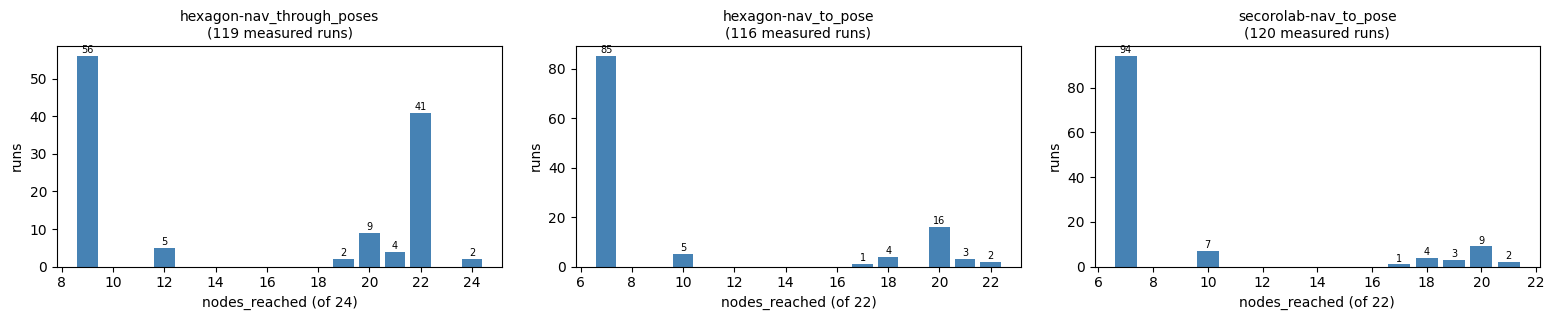

In [15]:
n = len(RESULTS)
ncol = min(3, n)
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3.3 * nrow), squeeze=False)
for ax, (key, r) in zip(axes.ravel(), RESULTS.items()):
    m = r["measured"]
    if not len(m):
        ax.set_visible(False)
        continue
    vc = m["nodes_reached"].value_counts().sort_index()
    ax.bar(vc.index, vc.values, color="steelblue")
    ax.set_title(f"{key}\n({len(m)} measured runs)", fontsize=10)
    ax.set_xlabel(f"nodes_reached (of {r['n_declared']})")
    ax.set_ylabel("runs")
    for x, y in vc.items():
        ax.annotate(f"{y}", (x, y), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7)
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

## 6. Across campaigns: which nodes were covered

The table below is the fraction of measured runs in which each declared node left `INVALID`,
one column per campaign. The core navigation nodes fire in ~every run; the recovery payload
(`ClearLocalCostmap-Context`, `Wait`, `BackUp`, `Spin`, the `WouldA*RecoveryHelp` guards and
the whole `RecoveryFallback -> RecoveryActions -> ClearingActions` chain) fires only in the
stuck population. The score is *breadth of code ticked*, and the cheapest way to raise it is
to get the robot stuck so the recovery subtree runs once.

fraction of measured runs in which each node left INVALID (n per campaign: {'hexagon-nav_through_poses': 119, 'hexagon-nav_to_pose': 116, 'secorolab-nav_to_pose': 120})
                              hexagon-nav_through_poses  hexagon-nav_to_pose  secorolab-nav_to_pose
node                                                                                               
BackUp                                            0.361                0.181                  0.092
ClearGlobalCostmap-Context                        0.017                0.060                  0.083
ClearGlobalCostmap-Subtree                        0.487                0.224                  0.158
ClearLocalCostmap-Context                         0.529                0.224                  0.142
ClearLocalCostmap-Subtree                         0.487                0.224                  0.158
ClearingActions                                   0.487                0.224                  0.158
ComputePathThroughPoses        

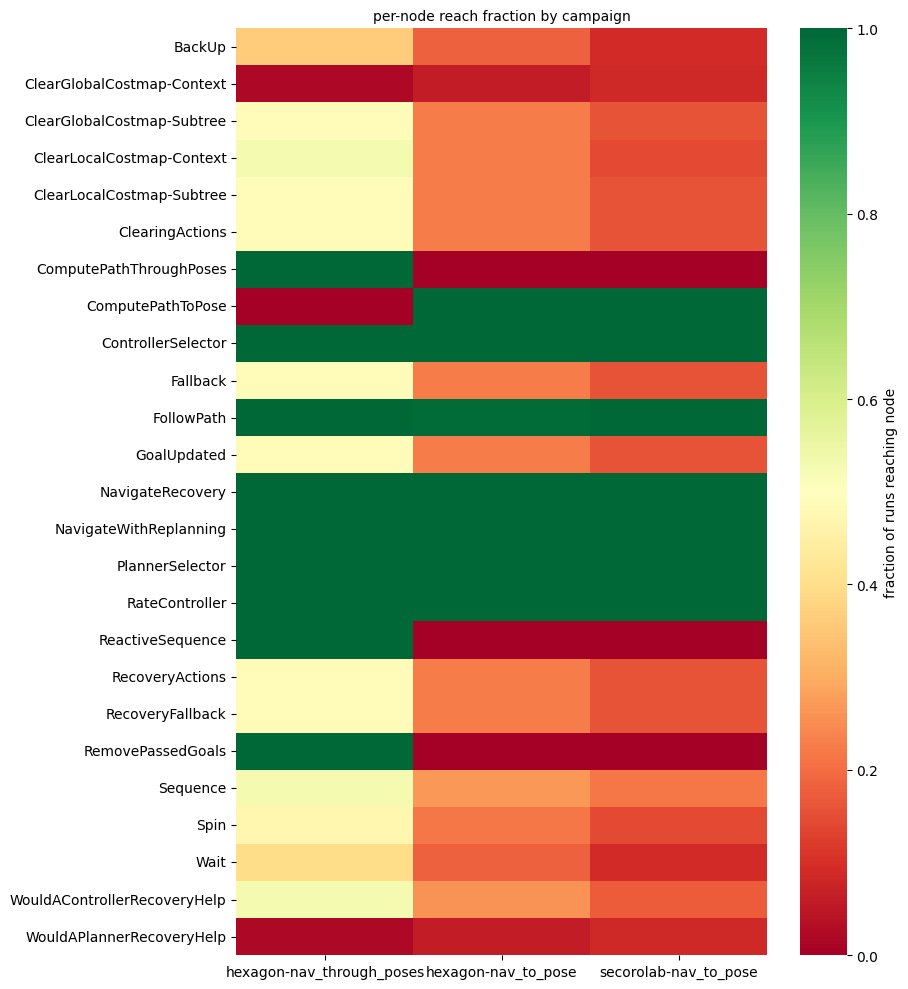

In [16]:
tbl = pd.DataFrame({key: pd.Series(r["node_frac"]) for key, r in RESULTS.items()})
tbl = tbl.reindex(sorted(tbl.index))
tbl.index.name = "node"
print(f"fraction of measured runs in which each node left INVALID "
      f"(n per campaign: { {k: len(r['measured']) for k, r in RESULTS.items()} })")
print(tbl.round(3).fillna(0).to_string())
tbl.round(4).to_csv(DATA_ROOT / "truely_random" / "node_reach_fractions.csv")

if len(tbl.columns):
    fig, ax = plt.subplots(figsize=(1.4 * len(tbl.columns) + 5, 0.32 * len(tbl) + 2))
    sns.heatmap(tbl.fillna(0), cmap="RdYlGn", vmin=0, vmax=1, ax=ax,
                cbar_kws={"label": "fraction of runs reaching node"})
    ax.set_title("per-node reach fraction by campaign", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    plt.tight_layout(); plt.show()

In [17]:
summary = pd.DataFrame([summary_row(r) for r in RESULTS.values()]).set_index("campaign")
summary.to_csv(DATA_ROOT / "truely_random" / "random_campaign_summary.csv")

print("full per-campaign summary:")
print(summary.to_string())

table3 = pd.DataFrame({
    "Task": [r["camp"]["task"] for r in RESULTS.values()],
    "Env.": [r["camp"]["world_label"] for r in RESULTS.values()],
    "Best mean coverage": [f"{r['best_cfg_cov']:.1%}" for r in RESULTS.values()],
    "Runs at 100%": [f"{100 * (r['measured']['nodes_reached'] == r['n_declared']).sum() / len(r['measured']):.1f}%"
                     if len(r["measured"]) else "--" for r in RESULTS.values()],
    "Failure-free runs": [f"{100 * (r['measured']['nodes_reached'] == r['failure_free_nodes']).sum() / len(r['measured']):.1f}%"
                          if len(r["measured"]) else "--" for r in RESULTS.values()],
}, index=summary.index)
print("\nTable III-style coverage summary (random campaigns):")
print(table3.to_string())


def _tex_row(r):
    c = r["camp"]
    m = r["measured"]
    n = len(m)
    task = TASK_TEX.get(c["task"], c["task"])
    env = ENV_TEX.get(c["world"], c["world"])
    best = f"\\qty{{{100 * r['best_cfg_cov']:.1f}}}{{\\percent}}" if pd.notna(r["best_cfg_cov"]) else "--"
    p100 = f"\\qty{{{100 * (m['nodes_reached'] == r['n_declared']).sum() / n:.1f}}}{{\\percent}}" if n else "--"
    pff = f"\\qty{{{100 * (m['nodes_reached'] == r['failure_free_nodes']).sum() / n:.1f}}}{{\\percent}}" if n else "--"
    return f"{task:<20s} & {env:<14s} & {best} & {p100} & {pff} \\\\"


tex = [
    r"\begin{tabular}{llrrr}",
    r"\toprule",
    r"\textbf{Task} & \textbf{Env.}",
    r"  & \shortstack{Best mean\\coverage}",
    r"  & \shortstack{Runs\\at 100\%}",
    r"  & \shortstack{Failure-free \\runs} \\",
    r"\midrule",
] + [_tex_row(r) for r in RESULTS.values()] + [r"\bottomrule", r"\end{tabular}"]
tex_src = "\n".join(tex)
(DATA_ROOT / "truely_random" / "random_coverage_summary.tex").write_text(tex_src + "\n")
print("\nLaTeX for the paper (truely_random/random_coverage_summary.tex):")
print(tex_src)

full per-campaign summary:
                                         world               task  n_configs  n_measured  nodes_declared  best_mean_coverage best_config  best_run_coverage  runs_at_100  runs_at_100_pct  failure_free_nodes  failure_free_n  failure_free_pct  coverage_mean  coverage_median  baseline_n  baseline_frac  nodes_union  nodes_never  n_none  n_all3
campaign                                                                                                                                                                                                                                                                                                                                            
hexagon-nav_through_poses              hexagon  nav_through_poses        120         119              24               1.000      tr-044              1.000            2              1.7                   9              56              47.1          0.636            0.500          56        

## 7. Across campaigns: coverage structure and the behaviour-server payload

`behaviour_kinds` is how many of `Spin`/`Wait`/`BackUp` fired. Runs that satisfy the task
cleanly fire only the core navigation spine; runs that get stuck fire `FollowPath` and then
the whole recovery playbook, which is what pushes coverage to the top of the range. So the
high-coverage mode is the *stuck* population, not well-travelled navigation.

[hexagon-nav_through_poses] behaviour_kinds value counts:
behaviour_kinds
0    63
1     9
2     4
3    43

coverage by behaviour_kinds:
                 count   mean    min    max
behaviour_kinds                            
0                   63  0.398  0.375  0.792
1                    9  0.833  0.833  0.833
2                    4  0.875  0.875  0.875
3                   43  0.921  0.917  1.000
[hexagon-nav_to_pose] behaviour_kinds value counts:
behaviour_kinds
0    91
1     4
3    21

coverage by behaviour_kinds:
                 count   mean    min    max
behaviour_kinds                            
0                   91  0.331  0.318  0.773
1                    4  0.818  0.818  0.818
3                   21  0.924  0.909  1.000
[secorolab-nav_to_pose] behaviour_kinds value counts:
behaviour_kinds
0    103
1      6
3     11

coverage by behaviour_kinds:
                 count   mean    min    max
behaviour_kinds                            
0                  103  0.337  0.318  0.864

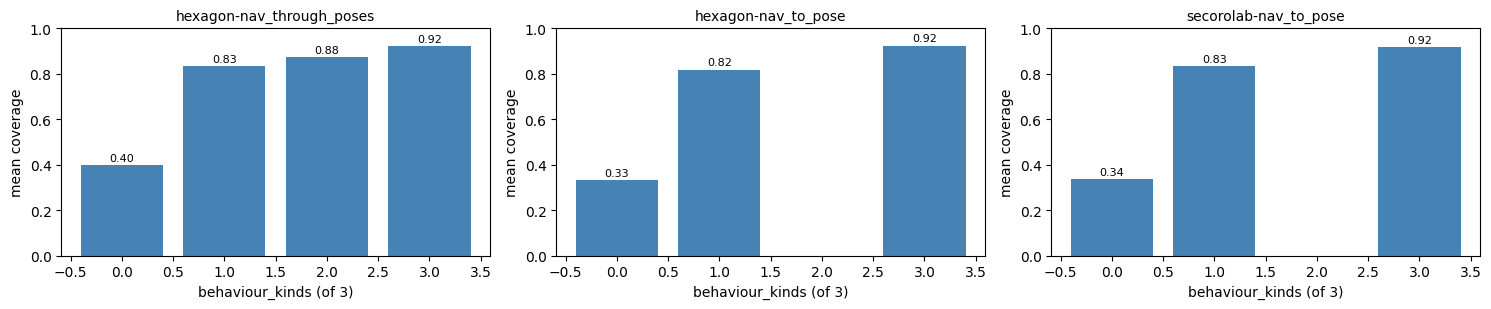

In [18]:
for key, r in RESULTS.items():
    m = r["measured"]
    if not len(m):
        continue
    print("=" * 60)
    print(f"[{key}] behaviour_kinds value counts:")
    print(m["behaviour_kinds"].value_counts().sort_index().to_string())
    print("\ncoverage by behaviour_kinds:")
    print(m.groupby("behaviour_kinds")["coverage"].agg(["count", "mean", "min", "max"])
          .round(3).to_string())

fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 3.2), squeeze=False)
for ax, (key, r) in zip(axes[0], RESULTS.items()):
    m = r["measured"]
    if not len(m):
        ax.set_visible(False)
        continue
    means = m.groupby("behaviour_kinds")["coverage"].mean()
    ax.bar(means.index, means.values, color="steelblue")
    ax.set_ylim(0, 1)
    ax.set_xlabel("behaviour_kinds (of 3)")
    ax.set_ylabel("mean coverage")
    ax.set_title(key, fontsize=10)
    for x, y in means.items():
        ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8)
plt.tight_layout(); plt.show()

## 8. Across campaigns: scenario parameters vs coverage

Each campaign randomises controller, planner, static/dynamic obstacles and the start/goal
pair. The per-campaign split below shows how each factor moves coverage and the behaviour
kinds. Path length is the straight-line start-goal distance of the drawn configuration.

In [19]:
for key, r in RESULTS.items():
    pall = r["pall"]
    if not len(pall):
        continue
    print("=" * 60)
    print(f"[{key}] scenario effects on coverage")
    for col in ["controller", "astar", "static", "dynamic"]:
        if col not in pall.columns or pall[col].isna().all():
            continue
        print(f"\n  -- {col} --")
        print("  " + pall.groupby(col)[["coverage", "kinds"]].mean().round(3)
              .to_string().replace("\n", "\n  "))
    if "path_len" in pall.columns:
        print("\n  correlation of path_len with coverage/kinds: "
              + pall[["path_len", "coverage", "kinds"]].corr().round(3)
              .loc[["coverage", "kinds"], "path_len"].to_string().replace("\n", "\n  "))

[hexagon-nav_through_poses] scenario effects on coverage

  -- controller --
              coverage  kinds
  controller                 
  DWB            0.615  1.246
  MPPI           0.657  1.207

  -- astar --
         coverage  kinds
  astar                 
  False     0.628  1.179
  True      0.646  1.288

  -- static --
          coverage  kinds
  static                 
  False      0.621  1.076
  True       0.654  1.415

  -- dynamic --
           coverage  kinds
  dynamic                 
  False       0.639  1.309
  True        0.633  1.156

  correlation of path_len with coverage/kinds: coverage   -0.096
  kinds      -0.069
[hexagon-nav_to_pose] scenario effects on coverage

  -- controller --
              coverage  kinds
  controller                 
  DWB            0.505  0.814
  MPPI           0.404  0.333

  -- astar --
         coverage  kinds
  astar                 
  False     0.478  0.652
  True      0.425  0.480

  -- static --
          coverage  kinds
  static 

## 9. Summary

* **The coverage numbers are real.** `nodes_total` equals the tree's distinct-name count in
  every measured run, and `nodes_reached` reproduces exactly by counting non-`INVALID` rows of
  `nav2_behaviors.csv`. The `INVALID` baseline rows are the trap: count `status_name != IDLE`
  instead and every run looks 100 % covered.
* **Coverage is discrete**, with a clean-navigation baseline at the minimum node count
  (7/22 for `nav_to_pose`), a few intermediate groups, and a stuck/recovery population at the
  top. A handful of draws reach every declared node.
* **The Table III-style summary** gives, per random campaign, the best single-configuration
  coverage, the share of runs at 100 % coverage and the share of failure-free runs -- directly
  comparable to the QD campaigns in the paper. It is regenerated automatically as new
  campaigns are added to `truely_random/`.

## 10. Coverage summary (paper Table III, quick reference)

The paper's Table III summarises each QD campaign by:

* **Best mean coverage** -- the highest mean per-run coverage of any concrete scenario;
* **Runs at 100\%** -- the share of the campaign's runs that activated every declared node;
* **Failure-free runs** -- the share of runs that activated no recovery node and only reached
  the minimum coverage (here exactly 7/22 nodes for the `nav_to_pose` tree).

The table below reproduces exactly those three columns for the random campaigns, so the random
baseline is directly comparable to the QD numbers. The failure-free node count is read from
the data (the minimum observed `nodes_reached`), so it adapts automatically when the
`nav_through_poses` / `follow_waypoints` trees arrive. A LaTeX-ready version is written to
`truely_random/random_coverage_summary.tex`.

In [20]:
summary = pd.DataFrame([summary_row(r) for r in RESULTS.values()]).set_index("campaign")
summary.to_csv(DATA_ROOT / "truely_random" / "random_campaign_summary.csv")

print("full per-campaign summary:")
print(summary.to_string())

table3 = pd.DataFrame({
    "Task": [r["camp"]["task"] for r in RESULTS.values()],
    "Env.": [r["camp"]["world_label"] for r in RESULTS.values()],
    "Best mean coverage": [f"{r['best_cfg_cov']:.1%}" for r in RESULTS.values()],
    "Runs at 100%": [f"{100 * (r['measured']['nodes_reached'] == r['n_declared']).sum() / len(r['measured']):.1f}%"
                     if len(r["measured"]) else "--" for r in RESULTS.values()],
    "Failure-free runs": [f"{100 * (r['measured']['nodes_reached'] == r['failure_free_nodes']).sum() / len(r['measured']):.1f}%"
                          if len(r["measured"]) else "--" for r in RESULTS.values()],
}, index=summary.index)
print("\nTable III-style coverage summary (random campaigns):")
print(table3.to_string())


def _tex_row(r):
    c = r["camp"]
    m = r["measured"]
    n = len(m)
    task = TASK_TEX.get(c["task"], c["task"])
    env = ENV_TEX.get(c["world"], c["world"])
    best = f"\\qty{{{100 * r['best_cfg_cov']:.1f}}}{{\\percent}}" if pd.notna(r["best_cfg_cov"]) else "--"
    p100 = f"\\qty{{{100 * (m['nodes_reached'] == r['n_declared']).sum() / n:.1f}}}{{\\percent}}" if n else "--"
    pff = f"\\qty{{{100 * (m['nodes_reached'] == r['failure_free_nodes']).sum() / n:.1f}}}{{\\percent}}" if n else "--"
    return f"{task:<20s} & {env:<14s} & {best} & {p100} & {pff} \\\\"


tex = [
    r"\begin{tabular}{llrrr}",
    r"\toprule",
    r"\textbf{Task} & \textbf{Env.}",
    r"  & \shortstack{Best mean\\coverage}",
    r"  & \shortstack{Runs\\at 100\%}",
    r"  & \shortstack{Failure-free \\runs} \\",
    r"\midrule",
] + [_tex_row(r) for r in RESULTS.values()] + [r"\bottomrule", r"\end{tabular}"]
tex_src = "\n".join(tex)
(DATA_ROOT / "truely_random" / "random_coverage_summary.tex").write_text(tex_src + "\n")
print("\nLaTeX for the paper (truely_random/random_coverage_summary.tex):")
print(tex_src)

full per-campaign summary:
                                         world               task  n_configs  n_measured  nodes_declared  best_mean_coverage best_config  best_run_coverage  runs_at_100  runs_at_100_pct  failure_free_nodes  failure_free_n  failure_free_pct  coverage_mean  coverage_median  baseline_n  baseline_frac  nodes_union  nodes_never  n_none  n_all3
campaign                                                                                                                                                                                                                                                                                                                                            
hexagon-nav_through_poses              hexagon  nav_through_poses        120         119              24               1.000      tr-044              1.000            2              1.7                   9              56              47.1          0.636            0.500          56        